# E1: calibrated probabilities for the saved 35- and 91-feature SVMs

This is a testing experiment. Keep the original `results_91/svm_35.joblib` and
`results_91/svm_91.joblib` unchanged. Save separate calibrated model files.

The originals were fitted on training plus validation. Generate out-of-fold decision
scores on those development clips with five speaker-separated folds. Fit sigmoid
calibration to those scores. With `ensemble=False`, scikit-learn then refits each SVM
on all development clips. Check its decision scores against the original model.
The scaler is fitted inside each fold. Test clips do not enter calibration or fitting.

Keep each original model's saved feature columns fixed. The 35-feature selection used
development data, so its calibration folds do not independently evaluate feature selection.
This is an exploratory probability check. The existing test set has also been examined
in earlier experiments; it is not a new independent confirmation.

Use threshold **0.50**: Singapore (`1`) if `p_singapore >= 0.50`, otherwise
Non-Singapore (`0`). Probabilities do not detect OOD audio. Do not transfer the separate
39-feature model's 0.80 threshold to these models.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
from time import perf_counter

import joblib
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import balanced_accuracy_score, brier_score_loss, confusion_matrix, log_loss
from sklearn.model_selection import StratifiedGroupKFold
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
STUDY_DIR = PROJECT_ROOT / 'outputs/e1_feature_study_accent_3to6s_upstream'
RESULTS_DIR = STUDY_DIR / 'svm_calibrated_probability_testing'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT))
from scripts.accent_study_data import load_shared_39_cache

RANDOM_SEED = 42
CV_FOLDS = 5
THRESHOLD = 0.50  # Fixed for this experiment; no threshold search.
COUNTS = (35, 91)

def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

shared = load_shared_39_cache(PROJECT_ROOT, STUDY_DIR)
with np.load(STUDY_DIR / 'acoustic_features_91.npz', allow_pickle=False) as cache:
    X = cache['features'].copy()
    feature_names = cache['feature_names'].tolist()
    cache_id = str(cache['cache_id'].item())
    if not np.array_equal(cache['clip_ids'].astype(str), shared['clip_ids']):
        raise ValueError('91-feature cache clip order differs from the validated base cache.')
    for key in ('labels', 'groups'):
        if not np.array_equal(cache[key], shared[key]):
            raise ValueError(f'91-feature cache {key} differ from the validated base cache.')
    if not np.array_equal(X[:, :39], shared['features']):
        raise ValueError('Base features differ between caches.')
expected_cache_id = hashlib.sha256(json.dumps({
    'base_cache_id': shared['cache_id'], 'clip_ids': shared['clip_ids'].tolist(),
    'delta_width': 9, 'delta_version': 1,
}, sort_keys=True).encode()).hexdigest()
if cache_id != expected_cache_id or X.shape != (len(shared['clip_ids']), 91) or not np.isfinite(X).all():
    raise ValueError('Invalid 91-feature cache identity or feature matrix.')
y, groups, clip_ids = shared['labels'], shared['groups'], shared['clip_ids']
metadata = shared['metadata']
dataset_id = shared['dataset_id']
# Preserve the original study's training-then-validation fitting order.
development_idx = np.concatenate([
    np.flatnonzero(metadata['split'].eq('train')),
    np.flatnonzero(metadata['split'].eq('validation')),
])
test_idx = np.flatnonzero(metadata['split'].eq('test'))
if set(groups[development_idx]) & set(groups[test_idx]):
    raise ValueError('Speaker overlap between development and test.')

originals, original_hashes = {}, {}
for count in COUNTS:
    path = STUDY_DIR / 'results_91' / f'svm_{count}.joblib'
    original_hashes[count] = file_hash(path)
    saved = joblib.load(path)
    if saved['cache_id'] != cache_id or saved['dataset_id'] != dataset_id:
        raise ValueError('Original model cache or dataset differs.')
    columns = saved['columns']
    if len(columns) != count or len(set(columns)) != count:
        raise ValueError('Incorrect original feature count.')
    if saved['feature_names'] != [feature_names[i] for i in columns]:
        raise ValueError('Original model feature order differs.')
    if list(saved['model'].classes_) != [0, 1]:
        raise ValueError('Expected class 1 to mean Singapore.')
    originals[count] = saved
print('scikit-learn:', sklearn.__version__)
print('Development clips:', len(development_idx), '| test clips:', len(test_idx))
print('Output directory:', RESULTS_DIR)

scikit-learn: 1.9.1
Development clips: 9750 | test clips: 1736
Output directory: /home/mh/nusproj/E1_Feature_Engineering/outputs/e1_feature_study_accent_3to6s_upstream/svm_calibrated_probability_testing


## 1. Prepare speaker-separated calibration folds

Each development clip supplies one held-out score. Its speaker must not occur in that
fold's fitting data. Both classes must occur on both sides of every fold.

In [2]:
splitter = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)
folds = list(splitter.split(X[development_idx], y[development_idx], groups[development_idx]))
held_counts = np.zeros(len(development_idx), dtype=int)
fold_rows = []
for fold, (fit, held) in enumerate(folds, start=1):
    fit_groups, held_groups = groups[development_idx[fit]], groups[development_idx[held]]
    if set(fit_groups) & set(held_groups):
        raise ValueError('Speaker overlap inside a calibration fold.')
    if set(y[development_idx[fit]]) != {0, 1} or set(y[development_idx[held]]) != {0, 1}:
        raise ValueError('Each fold must contain both classes on both sides.')
    held_counts[held] += 1
    fold_rows.append({'fold': fold, 'fit_clips': len(fit), 'held_clips': len(held),
        'fit_speakers': len(set(fit_groups)), 'held_speakers': len(set(held_groups))})
if not np.all(held_counts == 1):
    raise ValueError('Every development clip must be held out exactly once.')
display(pd.DataFrame(fold_rows))
pd.DataFrame(fold_rows).to_csv(RESULTS_DIR / 'calibration_folds.csv', index=False)

,fold,fit_clips,held_clips,fit_speakers,held_speakers
0,1,7800,1950,3137,784
1,2,7800,1950,3137,784
2,3,7800,1950,3137,784
3,4,7800,1950,3137,784
4,5,7800,1950,3136,785


## 2. Calibrate and save separate model files

Each `.joblib` file contains a model with `.predict()` and `.predict_proba()` methods.
It accepts the matching saved 35- or 91-feature order. Read its attached
`e1_probability_metadata_` attribute for columns and data identities.
The final SVM must reproduce the original decision scores before the file is saved.

In [3]:
calibrated_models, artifact_metadata = {}, {}
for count in COUNTS:
    saved = originals[count]
    columns = saved['columns']
    started = perf_counter()
    calibrated = CalibratedClassifierCV(
        estimator=clone(saved['model']), method='sigmoid', cv=folds, ensemble=False,
    )
    calibrated.fit(X[development_idx][:, columns], y[development_idx])
    refitted = calibrated.calibrated_classifiers_[0].estimator
    # Check all cached clips; this compares scores only and does not tune any setting.
    maximum_difference = 0.0
    for first in range(0, len(X), 1000):
        features = X[first:first + 1000][:, columns]
        original_scores = saved['model'].decision_function(features)
        refitted_scores = refitted.decision_function(features)
        np.testing.assert_allclose(refitted_scores, original_scores, rtol=1e-10, atol=1e-10)
        maximum_difference = max(maximum_difference, float(np.max(np.abs(refitted_scores - original_scores))))
    info = {
        'feature_count': count, 'columns': columns, 'feature_names': saved['feature_names'],
        'cache_id': cache_id, 'dataset_id': dataset_id,
        'source_model': f'results_91/svm_{count}.joblib', 'source_sha256': original_hashes[count],
        'calibration': 'sigmoid', 'ensemble': False, 'folds': CV_FOLDS,
        'speaker_grouped': True, 'random_seed': RANDOM_SEED,
        'fit_split': 'train_plus_validation', 'threshold': THRESHOLD,
        'decision_rule': 'Singapore (1) if p_singapore >= 0.50; otherwise Non-Singapore (0)',
        'fixed_feature_selection': True, 'purpose': 'exploratory_probability_testing',
        'maximum_original_score_difference': maximum_difference,
        'sklearn_version': sklearn.__version__,
    }
    calibrated.e1_probability_metadata_ = info
    destination = RESULTS_DIR / f'svm_{count}_calibrated.joblib'
    joblib.dump(calibrated, destination)
    (RESULTS_DIR / f'svm_{count}_calibrated_metadata.json').write_text(json.dumps(info, indent=2) + '\n')
    calibrated_models[count] = joblib.load(destination)
    artifact_metadata[count] = info
    assert file_hash(STUDY_DIR / 'results_91' / f'svm_{count}.joblib') == original_hashes[count]
    print(f'SVM {count}: calibrated and reloaded in {perf_counter() - started:.1f}s; '
          f'max original score difference = {maximum_difference:.3g}')
print('Original joblib files are unchanged.')

SVM 35: calibrated and reloaded in 8.4s; max original score difference = 0


SVM 91: calibrated and reloaded in 15.9s; max original score difference = 0
Original joblib files are unchanged.


## 3. Read class and probability outputs

`predict_proba()` returns one column per entry in `model.classes_`.
Use explicit names to avoid confusing Singapore probability with confidence in the
predicted class. `predicted_class` is 1 at or above 0.50; otherwise it is 0.
The helper accepts all 91 upstream features and selects the saved columns.

In [4]:
def predict_clip_probabilities(features_91, calibrated_model):
    features_91 = np.asarray(features_91)
    if features_91.ndim != 2 or features_91.shape[1] != 91 or not np.isfinite(features_91).all():
        raise ValueError('Expected finite upstream features with shape (n_clips, 91).')
    info = calibrated_model.e1_probability_metadata_
    selected = features_91[:, info['columns']]
    probability = calibrated_model.predict_proba(selected)
    classes = list(calibrated_model.classes_)
    p_singapore = probability[:, classes.index(1)]
    p_non_singapore = probability[:, classes.index(0)]
    predicted = (p_singapore >= info['threshold']).astype(int)
    # sklearn argmax uses class 0 for an exact tie; the explicit rule above uses class 1.
    return pd.DataFrame({'predicted_class': predicted,
        'p_singapore': p_singapore, 'p_non_singapore': p_non_singapore,
        'predicted_class_probability': np.where(predicted == 1, p_singapore, p_non_singapore)})

for count in COUNTS:
    print(f'SVM {count}: five example test clips')
    display(predict_clip_probabilities(X[test_idx[:5]], calibrated_models[count]).round(4))

# A standalone application can load the model and use its selected input columns:
# model = joblib.load(RESULTS_DIR / 'svm_35_calibrated.joblib')
# columns = model.e1_probability_metadata_['columns']
# probabilities = model.predict_proba(X_new_91[:, columns])
# classes = model.predict(X_new_91[:, columns])

SVM 35: five example test clips


,predicted_class,p_singapore,p_non_singapore,predicted_class_probability
0,0,0.0004,0.9996,0.9996
1,0,0.0002,0.9998,0.9998
2,0,0.0002,0.9998,0.9998
3,0,0.0018,0.9982,0.9982
4,0,0.0003,0.9997,0.9997


SVM 91: five example test clips


,predicted_class,p_singapore,p_non_singapore,predicted_class_probability
0,0,0.0002,0.9998,0.9998
1,0,0.0004,0.9996,0.9996
2,0,0.0003,0.9997,0.9997
3,0,0.0017,0.9983,0.9983
4,0,0.0029,0.9971,0.9971


## 4. Test probability diagnostics

Report Brier score and log loss on all test clips; lower is better.
A reliability plot compares mean predicted Singapore probability with the observed
Singapore fraction. Ten equal-count bins are descriptive and may hide variation.
The raw SVM supplies a matched class baseline, but has no calibrated probability
metrics. Do not change thresholds or select a model from these test diagnostics.

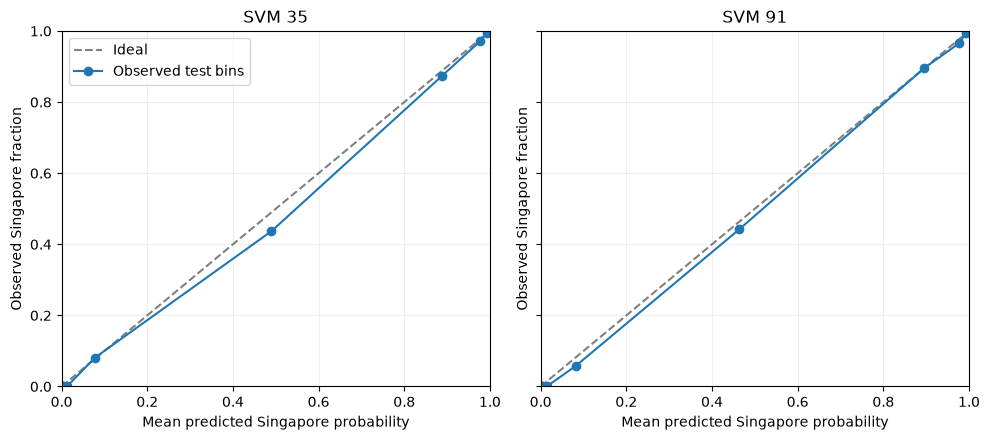

,feature_count,system,balanced_accuracy,singapore_recall,non_singapore_false_positive_rate,false_positive,false_negative,brier_score,log_loss
0,35,Original SVM,0.9440,0.9656,0.0776,76,26,NaN,NaN
1,35,Calibrated SVM at 0.50,0.9471,0.9524,0.0582,57,36,0.0424,0.1427
2,91,Original SVM,0.9444,0.9643,0.0755,74,27,NaN,NaN
3,91,Calibrated SVM at 0.50,0.9469,0.9458,0.0520,51,41,0.0398,0.1349


In [5]:
score_rows, outputs = [], []
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for count, axis in zip(COUNTS, axes):
    model = calibrated_models[count]
    result = predict_clip_probabilities(X[test_idx], model)
    result.insert(0, 'feature_count', count)
    result.insert(1, 'clip_id', clip_ids[test_idx])
    result.insert(2, 'speaker_group', groups[test_idx])
    result.insert(3, 'true_label', y[test_idx])
    raw_prediction = originals[count]['model'].predict(X[test_idx][:, originals[count]['columns']])
    result['original_svm_prediction'] = raw_prediction
    outputs.append(result)
    for name, prediction in [('Original SVM', raw_prediction),
                             ('Calibrated SVM at 0.50', result['predicted_class'].to_numpy())]:
        tn, fp, fn, tp = confusion_matrix(y[test_idx], prediction, labels=[0, 1]).ravel()
        calibrated = name.startswith('Calibrated')
        score_rows.append({'feature_count': count, 'system': name,
            'balanced_accuracy': balanced_accuracy_score(y[test_idx], prediction),
            'singapore_recall': tp / (tp + fn), 'non_singapore_false_positive_rate': fp / (tn + fp),
            'false_positive': int(fp), 'false_negative': int(fn),
            'brier_score': brier_score_loss(y[test_idx], result['p_singapore']) if calibrated else np.nan,
            'log_loss': log_loss(y[test_idx], result[['p_non_singapore', 'p_singapore']].to_numpy(), labels=[0, 1]) if calibrated else np.nan})
    fraction, mean_probability = calibration_curve(y[test_idx], result['p_singapore'], n_bins=10, strategy='quantile')
    axis.plot([0, 1], [0, 1], '--', color='gray', label='Ideal')
    axis.plot(mean_probability, fraction, 'o-', label='Observed test bins')
    axis.set(title=f'SVM {count}', xlabel='Mean predicted Singapore probability',
             ylabel='Observed Singapore fraction', xlim=(0, 1), ylim=(0, 1))
    axis.grid(alpha=.2)
axes[0].legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'test_probability_reliability.png', dpi=180, bbox_inches='tight')
plt.show()
test_summary = pd.DataFrame(score_rows)
test_predictions = pd.concat(outputs, ignore_index=True)
display(test_summary.round(4))
test_summary.to_csv(RESULTS_DIR / 'test_summary.csv', index=False)
test_predictions.to_csv(RESULTS_DIR / 'test_probability_predictions.csv', index=False)

## 5. Check saved inference and read the results

These separate calibrated models output probabilities for testing. Their default
class prediction uses the largest class probability (normally the 0.50 boundary).
For an exact 0.50 tie, the helper explicitly assigns Singapore; sklearn `.predict()`
assigns class 0. Use the helper if the inclusive threshold rule matters.

The calibration is tied to each model and feature representation. A high probability
does not establish that an OOD clip belongs to a familiar recording domain.
Keep the original feature-study model choice separate from this probability experiment.

In [6]:
for count in COUNTS:
    model = joblib.load(RESULTS_DIR / f'svm_{count}_calibrated.joblib')
    rows = predict_clip_probabilities(X[test_idx], model)
    np.testing.assert_allclose(rows['p_singapore'] + rows['p_non_singapore'], 1.0)
    assert rows[['p_singapore', 'p_non_singapore']].ge(0).all().all()
    assert rows[['p_singapore', 'p_non_singapore']].le(1).all().all()
    direct = model.predict(X[test_idx][:, model.e1_probability_metadata_['columns']])
    not_tie = rows['p_singapore'].to_numpy() != 0.50
    np.testing.assert_array_equal(direct[not_tie], rows['predicted_class'].to_numpy()[not_tie])
    assert file_hash(STUDY_DIR / 'results_91' / f'svm_{count}.joblib') == original_hashes[count]
    print(f'svm_{count}_calibrated.joblib: class/probability checks passed.')
print('Saved calibrated models, metadata, and test outputs:', RESULTS_DIR)

svm_35_calibrated.joblib: class/probability checks passed.


svm_91_calibrated.joblib: class/probability checks passed.
Saved calibrated models, metadata, and test outputs: /home/mh/nusproj/E1_Feature_Engineering/outputs/e1_feature_study_accent_3to6s_upstream/svm_calibrated_probability_testing
